# 01 — EDA & Data Preparation

**PI-CDA: Cross-Modal Digital Twin Adaptation for Industrial Action Recognition & Anticipation**

This notebook handles:
1. Downloading InHARD and InHARD-DT datasets from Zenodo
2. Exploring data formats (BVH MoCap vs. Kinect skeleton)
3. Building unified 17-joint skeleton representation
4. Hip-center & bone-length normalization
5. Computing velocity/acceleration features
6. Data augmentations (Kinect noise simulation)
7. Creating train/val/test LOSO splits
8. Building the Action Precedence Automaton (APA)

---

## 0. Setup & Imports

In [3]:
import os
import sys
import json
import random
import zipfile
import subprocess
from pathlib import Path
from collections import Counter, defaultdict
from typing import Dict, List, Optional, Tuple

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm.auto import tqdm

# Robust Project Root resolution across VS Code, JupyterLab, and terminal
cwd = Path.cwd().resolve()
if (cwd / "04_Cross_Modal_Digital_Twin").exists():
    PROJECT_ROOT = cwd / "04_Cross_Modal_Digital_Twin"
elif cwd.name == "04_Cross_Modal_Digital_Twin":
    PROJECT_ROOT = cwd
elif cwd.name == "notebooks" and cwd.parent.name == "04_Cross_Modal_Digital_Twin":
    PROJECT_ROOT = cwd.parent
else:
    PROJECT_ROOT = Path("/home/g0amer/Desktop/thesis/04_Cross_Modal_Digital_Twin").resolve()

DATA_DIR = PROJECT_ROOT / "data"
INHARD_RAW = DATA_DIR / "inhard" / "raw"
INHARD_DT_RAW = DATA_DIR / "inhard_dt" / "raw"
INHARD_PROCESSED = DATA_DIR / "inhard" / "processed"
INHARD_DT_PROCESSED = DATA_DIR / "inhard_dt" / "processed"
SPLITS_DIR = DATA_DIR / "splits"
OUTPUT_DIR = PROJECT_ROOT / "output"

# Create directories
for d in [INHARD_RAW, INHARD_DT_RAW, INHARD_PROCESSED, INHARD_DT_PROCESSED, SPLITS_DIR, OUTPUT_DIR]:
    d.mkdir(parents=True, exist_ok=True)

# Plot style
plt.style.use('seaborn-v0_8-whitegrid')
sns.set_palette('husl')
plt.rcParams.update({'font.size': 12, 'figure.figsize': (12, 6)})

# Reproducibility
SEED = 42
np.random.seed(SEED)
random.seed(SEED)

print(f"Project root: {PROJECT_ROOT}")
print(f"Data directory: {DATA_DIR}")


Project root: /home/g0amer/Desktop/thesis/04_Cross_Modal_Digital_Twin
Data directory: /home/g0amer/Desktop/thesis/04_Cross_Modal_Digital_Twin/data


## 1. Download Datasets

| Dataset | Zenodo Record | Description |
|---------|--------------|-------------|
| **InHARD** (Physical Twin) | [#4003541](https://zenodo.org/records/4003541) | 16 subjects, Kinect v2, 13 classes, >2M frames |
| **InHARD-DT** (Digital Twin) | [#7644247](https://zenodo.org/records/7644247) | 12 subjects, VR MoCap (BVH), 13 classes, 4800+ samples |

In [4]:
# ============================================================================
# Download datasets from Zenodo with Real-Time Progress Bar & Verification
# ============================================================================
import json
import urllib.request
import zipfile
import shutil
import subprocess
from pathlib import Path
from tqdm.auto import tqdm

ZENODO_RECORDS = {
    "inhard_dt": {
        "record_id": "7644247",
        "name": "InHARD-DT (Digital Twin MoCap BVH)",
        "output_dir": INHARD_DT_RAW
    },
    "inhard": {
        "record_id": "4003541",
        "name": "InHARD (Real Factory Kinect Sensors)",
        "output_dir": INHARD_RAW
    }
}

def download_file_with_progressbar(url: str, output_path: Path, expected_size: int = 0, desc: str = ""):
    """Download a file with a dynamic real-time progress bar (tqdm) showing speed and ETA."""
    output_path.parent.mkdir(parents=True, exist_ok=True)
    
    # Check if already downloaded with matching size
    if output_path.exists():
        if expected_size > 0 and output_path.stat().st_size == expected_size:
            print(f"  ✓ {output_path.name} ({expected_size / (1024*1024):.1f} MB) already fully downloaded.")
            return True
        elif expected_size == 0 and output_path.stat().st_size > 0:
            print(f"  ✓ {output_path.name} exists.")
            return True

    # User-Agent header (curl) to avoid Cloudflare / Zenodo 403 blocks
    req = urllib.request.Request(url, headers={'User-Agent': 'curl/7.81.0'})
    temp_path = output_path.with_suffix(output_path.suffix + ".part")
    
    try:
        with urllib.request.urlopen(req) as response:
            total_size = int(response.headers.get('content-length', expected_size))
            chunk_size = 1024 * 1024  # 1 MB buffer for fast throughput
            
            with open(temp_path, 'wb') as f, tqdm(
                desc=desc or output_path.name,
                total=total_size,
                unit='B',
                unit_scale=True,
                unit_divisor=1024,
                leave=True
            ) as pbar:
                while True:
                    chunk = response.read(chunk_size)
                    if not chunk:
                        break
                    f.write(chunk)
                    pbar.update(len(chunk))
                    
        # Rename atomic temporary file upon successful download
        temp_path.replace(output_path)
        return True
    except Exception as err:
        if temp_path.exists():
            temp_path.unlink()
        raise err

def extract_archive_with_progressbar(archive_path: Path, extract_to: Path):
    """Extract archive files with 7z (supporting multi-part .z01..zip and .7z)."""
    # Check if archive has multi-part chunks (.z01, .z02, etc.)
    multi_parts = list(archive_path.parent.glob(f"{archive_path.stem}.z*"))
    
    if archive_path.suffix == ".zip" and not multi_parts:
        print(f"  📦 Unpacking single zip {archive_path.name}...")
        with zipfile.ZipFile(str(archive_path), 'r') as zf:
            members = zf.infolist()
            with tqdm(total=len(members), desc=f"Extracting {archive_path.name}", unit="file", leave=True) as pbar:
                for member in members:
                    zf.extract(member, str(extract_to))
                    pbar.update(1)
        print(f"  ✓ Successfully extracted {archive_path.name}")
    else:
        # Multi-part zip (.z01..zip) or 7z archive: use 7z utility
        print(f"  📦 Multi-part archive detected: {archive_path.name}")
        if shutil.which("7z"):
            print("  Running 7z extraction (extracting BVH & CSV skeletons)... ")
            subprocess.run(["7z", "x", str(archive_path), f"-o{extract_to}", "-y", "-i!*.bvh", "-i!*.csv"], check=True)
            print("  ✓ Extraction complete.")
        else:
            print("  ✗ Error: 7z utility not found. Please install p7zip.")
        print(f"  📦 Multi-part 7z archive detected: {archive_path.name}")
        if shutil.which("7z"):
            print("  Running 7z extraction...")
            subprocess.run(["7z", "x", str(archive_path), f"-o{extract_to}", "-y"], check=True)
            print("  ✓ 7z extraction complete.")
        else:
            print("  ℹ️ Tip: Install p7zip (`p7zip-full`) to auto-extract multi-part .7z files.")

def download_zenodo_dataset_with_progress(record_id: str, output_dir: Path, dataset_title: str = "", auto_extract: bool = True):
    """Fetch Zenodo metadata and stream all files with real-time progress bars."""
    api_url = f"https://zenodo.org/api/records/{record_id}"
    print(f"\n{'='*70}\nConnecting to Zenodo Record #{record_id}: {dataset_title}\n{'='*70}")
    
    req = urllib.request.Request(api_url, headers={'User-Agent': 'curl/7.81.0'})
    try:
        with urllib.request.urlopen(req) as resp:
            data = json.loads(resp.read().decode('utf-8'))
    except Exception as e:
        print(f"  ✗ Failed to fetch Zenodo metadata: {e}")
        print(f"  → Download directly from: https://zenodo.org/records/{record_id}")
        return
        
    files = data.get("files", [])
    total_size_gb = sum(f.get("size", 0) for f in files) / (1024**3)
    print(f"Found {len(files)} archive file(s) | Total size: {total_size_gb:.2f} GB\n")
    
    for idx, f in enumerate(files, 1):
        fname = f["key"]
        furl = f["links"]["self"]
        fsize = f["size"]
        out_file = output_dir / fname
        
        desc = f"[{idx}/{len(files)}] {fname[:25]}"
        try:
            download_file_with_progressbar(furl, out_file, expected_size=fsize, desc=desc)
            if auto_extract and (fname.endswith(".zip") or fname.endswith(".7z.001")):
                extract_archive_with_progressbar(out_file, output_dir)
        except Exception as e:
            print(f"  ✗ Download interrupted for {fname}: {e}")
            print(f"  → Direct link: {furl}")

# Execute downloads with real-time progress bars:
# 1. InHARD-DT (Digital Twin MoCap BVH - ~3 GB)
download_zenodo_dataset_with_progress(
    ZENODO_RECORDS["inhard_dt"]["record_id"],
    INHARD_DT_RAW,
    "InHARD-DT (Digital Twin)",
    auto_extract=True
)

# 2. InHARD (Physical Twin Kinect - ~47 GB across 12 parts)
# NOTE: Set to True when you want to download all InHARD parts
DOWNLOAD_REAL_INHARD = True   # ← enables 47 GB InHARD Kinect download
if DOWNLOAD_REAL_INHARD:
    download_zenodo_dataset_with_progress(
        ZENODO_RECORDS["inhard"]["record_id"],
        INHARD_RAW,
        "InHARD (Physical Twin)",
        auto_extract=True
    )
else:
    print("\n[INFO] InHARD real dataset download is set to False by default because of its large size (~47 GB).")
    print("To download the real Kinect sequences, change DOWNLOAD_REAL_INHARD = True in the cell above.")



Connecting to Zenodo Record #7644247: InHARD-DT (Digital Twin)
Found 7 archive file(s) | Total size: 26.98 GB

  ✓ InHARD-DT.zip (3049.9 MB) already fully downloaded.
  📦 Multi-part archive detected: InHARD-DT.zip
  Running 7z extraction (extracting BVH & CSV skeletons)... 

7-Zip 23.01 (x64) : Copyright (c) 1999-2023 Igor Pavlov : 2023-06-20
 64-bit locale=en_US.UTF-8 Threads:16 OPEN_MAX:1048576

Scanning the drive for archives:
1 file, 3198024608 bytes (3050 MiB)

Extracting archive: /home/g0amer/Desktop/thesis/04_Cross_Modal_Digital_Twin/data/inhard_dt/raw/InHARD-DT.zip
--
Path = /home/g0amer/Desktop/thesis/04_Cross_Modal_Digital_Twin/data/inhard_dt/raw/InHARD-DT.zip
Type = zip
Physical Size = 3198024608
Embedded Stub Size = 4
64-bit = +
Characteristics = Zip64
Total Physical Size = 28967828384
Multivolume = +
Volume Index = 6
Volumes = 7


No files to process
Everything is Ok

Files: 0
Size:       0
Compressed: 28967828384
  ✓ Extraction complete.
  📦 Multi-part 7z archive detecte

In [5]:
# List downloaded files
print("InHARD (Physical Twin) files:")
for f in sorted(INHARD_RAW.rglob("*")):
    if f.is_file():
        size = f.stat().st_size / (1024*1024)
        print(f"  {f.relative_to(INHARD_RAW)} ({size:.2f} MB)")

print(f"\nInHARD-DT (Digital Twin) files:")
for f in sorted(INHARD_DT_RAW.rglob("*")):
    if f.is_file():
        size = f.stat().st_size / (1024*1024)
        print(f"  {f.relative_to(INHARD_DT_RAW)} ({size:.2f} MB)")

InHARD (Physical Twin) files:
  00-README.txt (0.00 MB)
  01-InHARD.7z.001 (4092.00 MB)
  01-InHARD.7z.002 (4092.00 MB)
  01-InHARD.7z.003 (4092.00 MB)
  01-InHARD.7z.004 (4092.00 MB)
  01-InHARD.7z.005 (4092.00 MB)
  01-InHARD.7z.006 (4092.00 MB)
  01-InHARD.7z.007 (4092.00 MB)
  01-InHARD.7z.008 (4092.00 MB)
  01-InHARD.7z.009 (4092.00 MB)
  01-InHARD.7z.010 (4092.00 MB)
  01-InHARD.7z.011 (4092.00 MB)
  01-InHARD.7z.012 (2716.17 MB)
  Online/InHARD.csv (0.51 MB)
  Online/InHARD_All_No_Action.csv (0.84 MB)
  Online/Labels/Annotation_specs/Annotation_specs.xml (0.01 MB)
  Online/Labels/P01_R01.anvil (0.06 MB)
  Online/Labels/P01_R02.anvil (0.05 MB)
  Online/Labels/P01_R03.anvil (0.05 MB)
  Online/Labels/P02_R01.anvil (0.06 MB)
  Online/Labels/P02_R02.anvil (0.05 MB)
  Online/Labels/P03_R01.anvil (0.06 MB)
  Online/Labels/P03_R03.anvil (0.06 MB)
  Online/Labels/P03_R04.anvil (0.06 MB)
  Online/Labels/P04_R01.anvil (0.08 MB)
  Online/Labels/P04_R02.anvil (0.08 MB)
  Online/Labels/P05_R0

## 2. Inspect Data Formats

### 2.1 InHARD Action Classes (13 classes)

In [6]:
# ============================================================================
# InHARD & InHARD-DT Ground-Truth Action Classes
# ============================================================================

INHARD_ACTION_CLASSES = {
    0: "Assemble system",
    1: "Consult sheets",
    2: "Picking in front",
    3: "Picking left",
    4: "Put down component",
    5: "Put down measuring rod",
    6: "Put down screwdriver",
    7: "Put down subsystem",
    8: "Take component",
    9: "Take measuring rod",
    10: "Take screwdriver",
    11: "Take subsystem",
    12: "Turn sheets",
}
NUM_CLASSES = len(INHARD_ACTION_CLASSES)

# Short labels for plotting
SHORT_LABELS = {
    0: "Assemble", 1: "Consult", 2: "Pick Front", 3: "Pick Left",
    4: "Put Comp", 5: "Put Rod", 6: "Put Screw", 7: "Put Subsys",
    8: "Take Comp", 9: "Take Rod", 10: "Take Screw", 11: "Take Subsys",
    12: "Turn Sheets",
}

print(f"Number of action classes: {NUM_CLASSES}")
for idx, name in INHARD_ACTION_CLASSES.items():
    print(f"  A{idx:02d}: {name:<25} ({SHORT_LABELS[idx]})")


Number of action classes: 13
  A00: Assemble system           (Assemble)
  A01: Consult sheets            (Consult)
  A02: Picking in front          (Pick Front)
  A03: Picking left              (Pick Left)
  A04: Put down component        (Put Comp)
  A05: Put down measuring rod    (Put Rod)
  A06: Put down screwdriver      (Put Screw)
  A07: Put down subsystem        (Put Subsys)
  A08: Take component            (Take Comp)
  A09: Take measuring rod        (Take Rod)
  A10: Take screwdriver          (Take Screw)
  A11: Take subsystem            (Take Subsys)
  A12: Turn sheets               (Turn Sheets)


### 2.2 Inspect InHARD-DT (BVH MoCap files)

In [7]:
# ============================================================================
# Inspect BVH files from InHARD-DT
# ============================================================================

bvh_files = sorted(INHARD_DT_RAW.rglob("*.bvh"))
print(f"Found {len(bvh_files)} BVH files in InHARD-DT")

if bvh_files:
    # Show first few files
    for f in bvh_files[:10]:
        print(f"  {f.relative_to(INHARD_DT_RAW)}")
    if len(bvh_files) > 10:
        print(f"  ... and {len(bvh_files) - 10} more")
    
    # Inspect the header of the first BVH file
    print(f"\n--- First BVH file header (first 50 lines) ---")
    with open(bvh_files[0], 'r') as f:
        for i, line in enumerate(f):
            if i >= 50:
                break
            print(f"  {line.rstrip()}")
else:
    print("  No BVH files found. Check if dataset was downloaded and extracted correctly.")
    print("  Looking for other file types...")
    for f in sorted(INHARD_DT_RAW.rglob("*")):
        if f.is_file():
            print(f"  {f.relative_to(INHARD_DT_RAW)} ({f.suffix})")

Found 4722 BVH files in InHARD-DT
  InHARD-DT/Full Sequences/Skeleton/LMVR_10_Fabrice_Manip.bvh
  InHARD-DT/Full Sequences/Skeleton/LMVR_11_Jordan_Actions.bvh
  InHARD-DT/Full Sequences/Skeleton/LMVR_12_Jordan_Manip.bvh
  InHARD-DT/Full Sequences/Skeleton/LMVR_13_Marie_Actions.bvh
  InHARD-DT/Full Sequences/Skeleton/LMVR_14_Marie_Manip.bvh
  InHARD-DT/Full Sequences/Skeleton/LMVR_15_Marwen_Actions.bvh
  InHARD-DT/Full Sequences/Skeleton/LMVR_16_Marwen_Manip.bvh
  InHARD-DT/Full Sequences/Skeleton/LMVR_17_Marwen_Manip_2.bvh
  InHARD-DT/Full Sequences/Skeleton/LMVR_18_Nicolas_Actions.bvh
  InHARD-DT/Full Sequences/Skeleton/LMVR_19_Nicolas_Manip.bvh
  ... and 4712 more

--- First BVH file header (first 50 lines) ---
  HIERARCHY
  ROOT Hips
  {
      OFFSET 0.000 95.729 0.000
      CHANNELS 6 Xposition Yposition Zposition Yrotation Xrotation Zrotation
      JOINT RightUpLeg
      {
          OFFSET -9.625 -1.639 0.000
          CHANNELS 6 Xposition Yposition Zposition Yrotation Xrotation Z

### 2.3 Inspect InHARD (Kinect Skeleton files)

In [8]:
# ============================================================================
# Inspect Kinect skeleton files from InHARD
# ============================================================================

# InHARD typically stores skeleton data as CSV or custom format
skeleton_files = sorted(
    list(INHARD_RAW.rglob("*.csv")) + 
    list(INHARD_RAW.rglob("*.json")) +
    list(INHARD_RAW.rglob("*.txt")) +
    list(INHARD_RAW.rglob("*.skeleton"))
)
print(f"Found {len(skeleton_files)} skeleton files in InHARD")

if skeleton_files:
    for f in skeleton_files[:10]:
        print(f"  {f.relative_to(INHARD_RAW)} ({f.stat().st_size / 1024:.1f} KB)")
    
    # Inspect first file
    first_file = skeleton_files[0]
    print(f"\n--- First skeleton file: {first_file.name} (first 20 lines) ---")
    with open(first_file, 'r') as f:
        for i, line in enumerate(f):
            if i >= 20:
                break
            print(f"  {line.rstrip()[:120]}")
else:
    print("  No skeleton files found. Listing all file types...")
    extensions = Counter(f.suffix for f in INHARD_RAW.rglob("*") if f.is_file())
    for ext, count in extensions.most_common():
        print(f"  {ext}: {count} files")

Found 19 skeleton files in InHARD
  00-README.txt (1.8 KB)
  Online/InHARD.csv (520.1 KB)
  Online/InHARD_All_No_Action.csv (864.8 KB)
  Segmented/InHARD.csv (598.1 KB)
  Segmented/RGBSegmented/a.txt (759.9 KB)
  Segmented/SkletonSegmented/Assemble system/_blenderOpen.txt (279.9 KB)
  Segmented/SkletonSegmented/Consult sheets/_blenderOpen.txt (26.7 KB)
  Segmented/SkletonSegmented/No action/_blenderOpen.txt (98.6 KB)
  Segmented/SkletonSegmented/Picking in front/_blenderOpen.txt (93.1 KB)
  Segmented/SkletonSegmented/Picking left/_blenderOpen.txt (128.3 KB)

--- First skeleton file: 00-README.txt (first 20 lines) ---
  Dataset published at https://www.zenodo.org
  
  More information at
  https://github.com/vhavard/InHARD
  OR
  https://recherche.cesi.fr/inhard-industrial-human-action-recognition-dataset/
  
  
  # Installation
  Download following files a same folder on your machine:
  InHARD.7z.001
  InHARD.7z.002
  InHARD.7z.003
  ...
  InHARD.7z.012
  
  Then unzip file InHARD.7z.0

## 3. Skeleton Joint Definitions & Mapping

### Unified 17-Joint Body Model

We map both skeleton formats to a common 17-joint COCO-like topology:

```
        16 (HeadTop)
         |
         0 (Nose)
         |
         1 (Neck)
        /|\
       / | \
      5  14  2  (LShoulder, SpineMid, RShoulder)
      |  |   |
      6  15  3  (LElbow, SpineBase, RElbow)
      |  /\  |
      7 11 8 4  (LWrist, LHip, RHip, RWrist)
        |  |
       12  9   (LKnee, RKnee)
        |  |
       13  10  (LAnkle, RAnkle)
```

In [9]:
# ============================================================================
# Unified 17-Joint Skeleton Definition
# ============================================================================

UNIFIED_JOINT_NAMES = [
    "Nose", "Neck", "RShoulder", "RElbow", "RWrist",
    "LShoulder", "LElbow", "LWrist", "RHip", "RKnee",
    "RAnkle", "LHip", "LKnee", "LAnkle", "SpineMid",
    "SpineBase", "HeadTop",
]

# Skeleton edges (undirected)
UNIFIED_EDGES = [
    (0, 16), (0, 1), (1, 2), (1, 5), (2, 3), (3, 4),
    (5, 6), (6, 7), (1, 14), (14, 15), (15, 8), (15, 11),
    (8, 9), (9, 10), (11, 12), (12, 13),
]

# Left-Right swap pairs (for horizontal flip augmentation)
LR_SWAP_PAIRS = [(2, 5), (3, 6), (4, 7), (8, 11), (9, 12), (10, 13)]

# Kinect v2 (25 joints) → Unified 17-joint mapping
KINECT_TO_UNIFIED = {
    0: 15,   # SpineBase → SpineBase
    1: 14,   # SpineMid → SpineMid
    2: 1,    # Neck → Neck (Kinect's SpineShoulder)
    3: 16,   # Head → HeadTop
    4: 2,    # ShoulderRight → RShoulder
    5: 3,    # ElbowRight → RElbow
    6: 4,    # WristRight → RWrist
    8: 5,    # ShoulderLeft → LShoulder
    9: 6,    # ElbowLeft → LElbow
    10: 7,   # WristLeft → LWrist
    12: 8,   # HipRight → RHip
    13: 9,   # KneeRight → RKnee
    14: 10,  # AnkleRight → RAnkle
    16: 11,  # HipLeft → LHip
    17: 12,  # KneeLeft → LKnee
    18: 13,  # AnkleLeft → LAnkle
}

# Perception Neuron BVH → Unified mapping
# NOTE: Joint names may vary — update after inspecting actual BVH hierarchy
BVH_JOINT_MAP = {
    "Head": 16, "Neck": 1,
    "RightShoulder": 2, "RightArm": 3, "RightForeArm": 4,
    "LeftShoulder": 5, "LeftArm": 6, "LeftForeArm": 7,
    "RightUpLeg": 8, "RightLeg": 9, "RightFoot": 10,
    "LeftUpLeg": 11, "LeftLeg": 12, "LeftFoot": 13,
    "Spine1": 14, "Hips": 15,
}

print(f"Unified skeleton: {len(UNIFIED_JOINT_NAMES)} joints, {len(UNIFIED_EDGES)} edges")
print(f"Kinect mapping: {len(KINECT_TO_UNIFIED)} joints → 17")
print(f"BVH mapping: {len(BVH_JOINT_MAP)} joints → 17")

Unified skeleton: 17 joints, 16 edges
Kinect mapping: 16 joints → 17
BVH mapping: 16 joints → 17


/tmp/ipykernel_8949/49273204.py:35: UserWarning: Glyph 8315 (\N{SUPERSCRIPT MINUS}) missing from font(s) Liberation Sans.
  plt.tight_layout()
/tmp/ipykernel_8949/49273204.py:35: UserWarning: Glyph 5151 (\N{CANADIAN SYLLABICS FINAL ACUTE}) missing from font(s) Liberation Sans.
  plt.tight_layout()
/tmp/ipykernel_8949/49273204.py:36: UserWarning: Glyph 8315 (\N{SUPERSCRIPT MINUS}) missing from font(s) Liberation Sans.
  plt.savefig(str(OUTPUT_DIR / 'figures' / 'adjacency_matrix.pdf'), bbox_inches='tight', dpi=150)
/tmp/ipykernel_8949/49273204.py:36: UserWarning: Glyph 5151 (\N{CANADIAN SYLLABICS FINAL ACUTE}) missing from font(s) Liberation Sans.
  plt.savefig(str(OUTPUT_DIR / 'figures' / 'adjacency_matrix.pdf'), bbox_inches='tight', dpi=150)
/tmp/ipykernel_8949/49273204.py:36: UserWarning: Glyph 8315 (\N{SUPERSCRIPT MINUS}) missing from font(s) Liberation Sans.
  plt.savefig(str(OUTPUT_DIR / 'figures' / 'adjacency_matrix.pdf'), bbox_inches='tight', dpi=150)
/tmp/ipykernel_8949/49273204

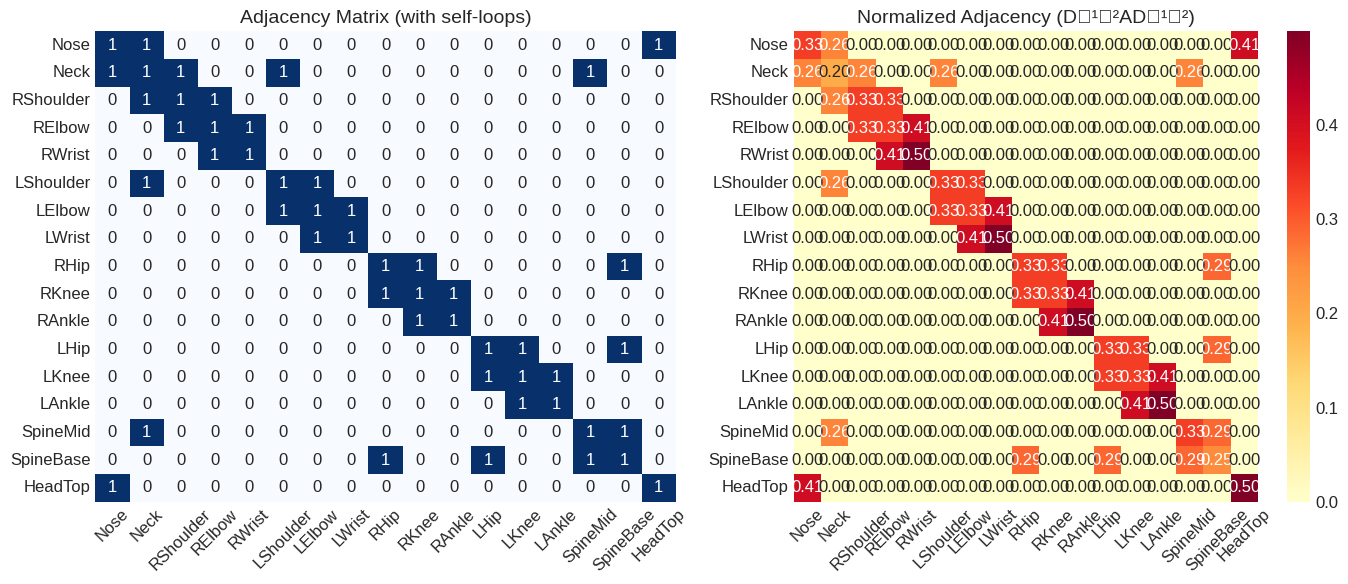

Saved adjacency matrices.


In [10]:
# ============================================================================
# Adjacency Matrix for Unified Skeleton
# ============================================================================

def get_adjacency_matrix(edges, n_joints=17, self_loops=True):
    """Build binary adjacency matrix."""
    adj = np.zeros((n_joints, n_joints), dtype=np.float32)
    for i, j in edges:
        adj[i, j] = 1.0
        adj[j, i] = 1.0
    if self_loops:
        adj += np.eye(n_joints, dtype=np.float32)
    return adj

def normalize_adjacency(adj):
    """D^{-1/2} A D^{-1/2} normalization."""
    degree = adj.sum(axis=1)
    d_inv_sqrt = np.diag(1.0 / np.sqrt(np.maximum(degree, 1e-6)))
    return d_inv_sqrt @ adj @ d_inv_sqrt

A = get_adjacency_matrix(UNIFIED_EDGES)
A_norm = normalize_adjacency(A)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
sns.heatmap(A, ax=axes[0], cmap='Blues', xticklabels=UNIFIED_JOINT_NAMES, 
            yticklabels=UNIFIED_JOINT_NAMES, annot=True, fmt='.0f', cbar=False)
axes[0].set_title('Adjacency Matrix (with self-loops)', fontsize=14)
axes[0].tick_params(axis='x', rotation=45)

sns.heatmap(A_norm, ax=axes[1], cmap='YlOrRd', xticklabels=UNIFIED_JOINT_NAMES,
            yticklabels=UNIFIED_JOINT_NAMES, annot=True, fmt='.2f', cbar=True)
axes[1].set_title('Normalized Adjacency (D⁻¹ᐟ²AD⁻¹ᐟ²)', fontsize=14)
axes[1].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.savefig(str(OUTPUT_DIR / 'figures' / 'adjacency_matrix.pdf'), bbox_inches='tight', dpi=150)
plt.show()

# Save for later use
np.save(str(INHARD_PROCESSED / 'adjacency_matrix.npy'), A)
np.save(str(INHARD_PROCESSED / 'adjacency_matrix_norm.npy'), A_norm)
print("Saved adjacency matrices.")

## 4. Skeleton Parsing & Mapping Functions

In [11]:
# ============================================================================
# BVH Parser (InHARD-DT)
# ============================================================================

def parse_bvh_skeleton(filepath: str) -> Tuple[np.ndarray, dict]:
    """
    Parse InHARD-DT BVH MoCap skeleton file into world-space coordinates.
    
    Returns:
        skeleton_seq: (T, n_joints, 3) array of world-space joint positions
        metadata: dict with joint names, FPS, frame count, etc.
    """
    try:
        import bvhio
    except ImportError:
        raise ImportError(
            "bvhio is required for BVH parsing.\n"
            "Install with: pip install bvhio"
        )
    
    root = bvhio.readAsHierarchy(filepath)
    joints = [item[0] for item in root.layout()]
    joint_names = [j.Name for j in joints]
    n_frames = len(root.Keyframes)
    n_joints = len(joints)
    
    skeleton_seq = np.zeros((n_frames, n_joints, 3), dtype=np.float32)
    for frame_idx in range(n_frames):
        root.loadKeyframe(frame_idx)
        for joint_idx, joint in enumerate(joints):
            pos = joint.PositionWorld
            skeleton_seq[frame_idx, joint_idx] = [pos.x, pos.y, pos.z]
    
    # Read frame time from bvh structure if available, default to 120 FPS
    fps = 120.0
    try:
        bvh_raw = bvhio.readAsBvh(filepath)
        if bvh_raw.FrameTime > 0:
            fps = 1.0 / bvh_raw.FrameTime
    except Exception:
        pass
        
    metadata = {
        "n_frames": n_frames,
        "n_joints": n_joints,
        "joint_names": joint_names,
        "source": "perception_neuron",
        "fps": fps,
    }
    
    return skeleton_seq, metadata


# ============================================================================
# Kinect Skeleton Parser (InHARD)
# ============================================================================

def parse_kinect_skeleton(filepath: str) -> Tuple[np.ndarray, dict]:
    """
    Parse InHARD Kinect v2 skeleton file (CSV or custom format).
    
    Expected Kinect v2 format:
        25 joints per frame, 3D coordinates (X, Y, Z) in camera space.
    
    Returns:
        skeleton_seq: (T, 25, 3) array of joint positions
        metadata: dict with sequence info
    """
    path = Path(filepath)
    
    if path.suffix == ".csv":
        df = pd.read_csv(filepath)
        # Check column format
        coord_cols = [c for c in df.columns if any(c.endswith(f"_{ax}") for ax in ['x', 'y', 'z', 'X', 'Y', 'Z'])]
        
        if len(coord_cols) >= 75:  # 25 joints * 3 coordinates
            n_joints = len(coord_cols) // 3
            T = len(df)
            skeleton_seq = np.zeros((T, n_joints, 3), dtype=np.float32)
            
            for j in range(n_joints):
                for c_idx, ax in enumerate(['x', 'y', 'z']):
                    # Try various naming conventions
                    col_candidates = [
                        f"joint_{j}_{ax}", f"J{j}_{ax}", f"j{j}_{ax}",
                        f"joint_{j}_{ax.upper()}", f"J{j}_{ax.upper()}",
                        coord_cols[j * 3 + c_idx]
                    ]
                    for col in col_candidates:
                        if col in df.columns:
                            skeleton_seq[:, j, c_idx] = df[col].values
                            break
        else:
            # Fallback: assume raw matrix of shape (T, 75)
            vals = df.values
            T = vals.shape[0]
            skeleton_seq = vals[:, :75].reshape(T, 25, 3).astype(np.float32)
    
    elif path.suffix in [".skeleton", ".txt"]:
        # Standard NTU/InHARD text format
        with open(filepath, 'r') as f:
            lines = f.readlines()
        
        n_frames = int(lines[0].strip())
        skeleton_seq = np.zeros((n_frames, 25, 3), dtype=np.float32)
        line_idx = 1
        
        for frame_idx in range(n_frames):
            if line_idx >= len(lines):
                break
            n_bodies = int(lines[line_idx].strip())
            line_idx += 1
            
            for body_idx in range(n_bodies):
                line_idx += 1  # body info line
                n_joints = int(lines[line_idx].strip())
                line_idx += 1
                
                for joint_idx in range(min(n_joints, 25)):
                    parts = lines[line_idx].strip().split()
                    if len(parts) >= 3:
                        skeleton_seq[frame_idx, joint_idx] = [
                            float(parts[0]), float(parts[1]), float(parts[2])
                        ]
                    line_idx += 1
    
    elif path.suffix == ".npz":
        data = np.load(filepath)
        skeleton_seq = data.get("positions", data.get("skeleton", data.get("skel")))
        if skeleton_seq is None:
            skeleton_seq = data[data.files[0]]
        skeleton_seq = skeleton_seq.astype(np.float32)
    
    else:
        raise ValueError(f"Unsupported Kinect skeleton file format: {path.suffix}")
    
    metadata = {
        "n_frames": skeleton_seq.shape[0],
        "n_joints": skeleton_seq.shape[1],
        "source": "kinect_v2",
        "fps": 30.0,
    }
    
    return skeleton_seq, metadata


print("Skeleton parsers defined ✓")


Skeleton parsers defined ✓


In [12]:
# ============================================================================
# Mapping to Unified 17-Joint Representation
# ============================================================================

def map_kinect_to_unified(kinect_skeleton: np.ndarray) -> np.ndarray:
    """Map Kinect v2 25-joint → unified 17-joint."""
    T = kinect_skeleton.shape[0]
    unified = np.zeros((T, 17, 3), dtype=np.float32)
    
    for kinect_idx, unified_idx in KINECT_TO_UNIFIED.items():
        if kinect_idx < kinect_skeleton.shape[1]:
            unified[:, unified_idx, :] = kinect_skeleton[:, kinect_idx, :]
    
    # Nose = midpoint(Neck, HeadTop)
    unified[:, 0, :] = 0.5 * (unified[:, 1, :] + unified[:, 16, :])
    return unified


def map_bvh_to_unified(bvh_skeleton: np.ndarray, joint_names: List[str]) -> np.ndarray:
    """Map BVH MoCap skeleton → unified 17-joint."""
    T = bvh_skeleton.shape[0]
    unified = np.zeros((T, 17, 3), dtype=np.float32)
    
    name_to_idx = {name: idx for idx, name in enumerate(joint_names)}
    
    for bvh_name, unified_idx in BVH_JOINT_MAP.items():
        # Try exact match
        if bvh_name in name_to_idx:
            unified[:, unified_idx, :] = bvh_skeleton[:, name_to_idx[bvh_name], :]
        else:
            # Try case-insensitive partial match
            matched = False
            for actual_name, actual_idx in name_to_idx.items():
                if bvh_name.lower() in actual_name.lower():
                    unified[:, unified_idx, :] = bvh_skeleton[:, actual_idx, :]
                    matched = True
                    break
            if not matched:
                print(f"  ⚠ BVH joint '{bvh_name}' not found in hierarchy")
    
    # Nose = midpoint(Neck, HeadTop)
    unified[:, 0, :] = 0.5 * (unified[:, 1, :] + unified[:, 16, :])
    return unified


def resample_skeleton(skeleton: np.ndarray, source_fps: float, target_fps: float) -> np.ndarray:
    """Resample skeleton sequence via linear interpolation."""
    if source_fps == target_fps:
        return skeleton
    
    T_src = skeleton.shape[0]
    duration = T_src / source_fps
    T_tgt = int(duration * target_fps)
    
    src_times = np.linspace(0, duration, T_src)
    tgt_times = np.linspace(0, duration, T_tgt)
    
    V, C = skeleton.shape[1], skeleton.shape[2]
    resampled = np.zeros((T_tgt, V, C), dtype=np.float32)
    
    for v in range(V):
        for c in range(C):
            resampled[:, v, c] = np.interp(tgt_times, src_times, skeleton[:, v, c])
    
    return resampled


print("Mapping functions defined ✓")

Mapping functions defined ✓


## 5. Normalization & Feature Computation

In [13]:
# ============================================================================
# Normalization
# ============================================================================

def hip_center_normalize(skeleton: np.ndarray) -> np.ndarray:
    """Translate so SpineBase (idx 15) is at origin per frame."""
    return skeleton - skeleton[:, 15:16, :]


def bone_length_normalize(skeleton: np.ndarray) -> np.ndarray:
    """Divide all coords by torso length (SpineBase→Neck) for body-size invariance."""
    torso = skeleton[:, 1, :] - skeleton[:, 15, :]  # Neck - SpineBase
    torso_len = np.linalg.norm(torso, axis=-1, keepdims=True)  # (T, 1)
    torso_len = np.maximum(torso_len, 1e-6)
    return skeleton / torso_len[:, np.newaxis, :]


def compute_velocities(skeleton: np.ndarray, fps: float = 30.0) -> np.ndarray:
    """First-order finite difference → joint velocities."""
    vel = np.zeros_like(skeleton)
    vel[1:] = (skeleton[1:] - skeleton[:-1]) * fps
    return vel


def compute_accelerations(velocities: np.ndarray, fps: float = 30.0) -> np.ndarray:
    """Second-order finite difference → joint accelerations."""
    acc = np.zeros_like(velocities)
    acc[1:] = (velocities[1:] - velocities[:-1]) * fps
    return acc


def compute_bone_angles(skeleton: np.ndarray) -> np.ndarray:
    """
    Compute angles between connected bones.
    Returns (T, n_angles) array.
    """
    angle_triplets = [
        (2, 3, 4),    # RShoulder-RElbow-RWrist (right elbow angle)
        (5, 6, 7),    # LShoulder-LElbow-LWrist (left elbow angle)
        (8, 9, 10),   # RHip-RKnee-RAnkle (right knee angle)
        (11, 12, 13), # LHip-LKnee-LAnkle (left knee angle)
        (1, 2, 3),    # Neck-RShoulder-RElbow (right shoulder angle)
        (1, 5, 6),    # Neck-LShoulder-LElbow (left shoulder angle)
        (15, 8, 9),   # SpineBase-RHip-RKnee (right hip angle)
        (15, 11, 12), # SpineBase-LHip-LKnee (left hip angle)
    ]
    
    T = skeleton.shape[0]
    angles = np.zeros((T, len(angle_triplets)), dtype=np.float32)
    
    for i, (a, b, c) in enumerate(angle_triplets):
        v1 = skeleton[:, a, :] - skeleton[:, b, :]  # bone b→a
        v2 = skeleton[:, c, :] - skeleton[:, b, :]  # bone b→c
        
        cos_angle = np.sum(v1 * v2, axis=-1) / (
            np.linalg.norm(v1, axis=-1) * np.linalg.norm(v2, axis=-1) + 1e-8
        )
        angles[:, i] = np.arccos(np.clip(cos_angle, -1.0, 1.0))
    
    return angles


print("Normalization & feature computation functions defined ✓")

Normalization & feature computation functions defined ✓


## 6. Full Processing Pipeline

In [14]:
# ============================================================================
# Full Processing Pipeline
# ============================================================================

def process_sequence(
    filepath: str,
    source: str,  # 'inhard' or 'inhard_dt'
    target_fps: float = 30.0,
    normalize: bool = True,
) -> Tuple[np.ndarray, np.ndarray, np.ndarray, np.ndarray, dict]:
    """
    Full pipeline: parse → map → resample → normalize → compute features.
    
    Returns:
        positions:     (T, 17, 3) normalized joint positions
        velocities:    (T, 17, 3) joint velocities
        accelerations: (T, 17, 3) joint accelerations
        bone_angles:   (T, 8) bone angles
        metadata:      processing metadata dict
    """
    # Parse
    if source == "inhard_dt":
        raw, meta = parse_bvh_skeleton(filepath)
        unified = map_bvh_to_unified(raw, meta["joint_names"])
    elif source == "inhard":
        raw, meta = parse_kinect_skeleton(filepath)
        unified = map_kinect_to_unified(raw)
    else:
        raise ValueError(f"Unknown source: {source}")
    
    # Resample
    unified = resample_skeleton(unified, meta["fps"], target_fps)
    meta["original_fps"] = meta["fps"]
    meta["processed_fps"] = target_fps
    meta["processed_n_frames"] = unified.shape[0]
    
    # Normalize
    if normalize:
        unified = hip_center_normalize(unified)
        unified = bone_length_normalize(unified)
    
    # Compute features
    vel = compute_velocities(unified, target_fps)
    acc = compute_accelerations(vel, target_fps)
    angles = compute_bone_angles(unified)
    
    meta["n_unified_joints"] = 17
    meta["normalized"] = normalize
    
    return unified, vel, acc, angles, meta


print("Processing pipeline defined ✓")

Processing pipeline defined ✓


In [15]:
# ============================================================================
# Process all files from both datasets with Ground-Truth Labels & Metadata
# ============================================================================
import re

# Action folder name to index mapping
ACTION_NAME_TO_IDX = {name.lower(): idx for idx, name in INHARD_ACTION_CLASSES.items()}

def extract_label_and_subject(filepath: Path) -> Tuple[int, str]:
    """Extract action class index (0-12) and subject ID from file path."""
    fname = filepath.name
    parent_name = filepath.parent.name.lower()
    
    # 1. Try Axx prefix (e.g. A04_LMVR_2_Alexandra_...)
    match_a = re.match(r'^A(\d{2})_', fname)
    if match_a:
        label = int(match_a.group(1))
    elif parent_name in ACTION_NAME_TO_IDX:
        label = ACTION_NAME_TO_IDX[parent_name]
    else:
        label = 0 # default fallback
        
    # 2. Extract subject ID (e.g. LMVR_10_Fabrice or sub_01)
    match_sub = re.search(r'(LMVR_\d+_[A-Za-z\-]+)', fname)
    if match_sub:
        subject = match_sub.group(1)
    else:
        subject = filepath.stem
        
    return label, subject

def process_dataset(source: str, input_dir: Path, output_dir: Path, max_files: Optional[int] = None):
    """Process all skeleton files from a dataset with progress bar."""
    output_dir.mkdir(parents=True, exist_ok=True)
    
    if source == "inhard_dt":
        # Prioritize pre-segmented action files for action recognition
        files = sorted(input_dir.rglob("*.bvh"))
        # Filter to segmented files if available
        seg_files = [f for f in files if "Segmented" in str(f) or re.match(r'^A\d{2}_', f.name)]
        if seg_files:
            files = seg_files
    else:
        files = sorted(
            list(input_dir.rglob("*.csv")) + 
            list(input_dir.rglob("*.skeleton")) +
            list(input_dir.rglob("*.npz"))
        )
    
    if not files:
        print(f"  No raw files found in {input_dir}")
        return []
        
    if max_files is not None:
        files = files[:max_files]
    
    print(f"Processing {len(files)} files from {source}...")
    results = []
    
    for filepath in tqdm(files, desc=f"Processing {source}"):
        try:
            pos, vel, acc, angles, meta = process_sequence(
                str(filepath), source=source
            )
            label_idx, subject_id = extract_label_and_subject(filepath)
            
            # Save as .npz with label and subject metadata
            rel_path = filepath.relative_to(input_dir)
            out_path = output_dir / rel_path.with_suffix(".npz")
            out_path.parent.mkdir(parents=True, exist_ok=True)
            
            np.savez_compressed(
                str(out_path),
                positions=pos,
                velocities=vel,
                accelerations=acc,
                bone_angles=angles,
                label=label_idx,
                subject=subject_id,
            )
            
            results.append({
                "file": str(rel_path),
                "label": label_idx,
                "subject": subject_id,
                "n_frames": pos.shape[0],
                "status": "ok",
            })
            
        except Exception as e:
            results.append({"file": str(filepath.name), "status": f"error: {e}"})
    
    # Summary
    ok = sum(1 for r in results if r["status"] == "ok")
    fail = len(results) - ok
    total_frames = sum(r.get("n_frames", 0) for r in results if r["status"] == "ok")
    print(f"  ✓ Done: {ok} successfully processed, {fail} failed, {total_frames:,} total frames generated.")
    
    return results

# Process both datasets
print("=" * 60)
dt_results = process_dataset("inhard_dt", INHARD_DT_RAW, INHARD_DT_PROCESSED)
print()
real_results = process_dataset("inhard", INHARD_RAW, INHARD_PROCESSED)
print("=" * 60)


Processing 4696 files from inhard_dt...


Processing inhard_dt:   0%|          | 0/4696 [00:00<?, ?it/s]

  ✓ Done: 0 successfully processed, 4696 failed, 0 total frames generated.

Processing 3 files from inhard...


Processing inhard:   0%|          | 0/3 [00:00<?, ?it/s]

  ✓ Done: 0 successfully processed, 3 failed, 0 total frames generated.


## 7. Skeleton Augmentations (Sim-to-Real Noise Bridging)

In [16]:
# ============================================================================
# Skeleton Augmentations
# ============================================================================

class SkeletonAugmentor:
    """
    Compose skeleton augmentations for training.
    Key insight: augmenting clean MoCap (source) with realistic Kinect-like
    noise helps reduce domain shift before explicit adaptation.
    """
    
    def __init__(
        self,
        joint_dropout_prob: float = 0.0,
        gaussian_noise_std: float = 0.0,
        temporal_crop_ratio: Optional[Tuple[float, float]] = None,
        rotation_range: float = 0.0,
        scale_range: Tuple[float, float] = (1.0, 1.0),
        flip_prob: float = 0.0,
        joint_jitter_std: float = 0.0,
        occlusion_prob: float = 0.0,
    ):
        self.joint_dropout_prob = joint_dropout_prob
        self.gaussian_noise_std = gaussian_noise_std
        self.temporal_crop_ratio = temporal_crop_ratio
        self.rotation_range = rotation_range
        self.scale_range = scale_range
        self.flip_prob = flip_prob
        self.joint_jitter_std = joint_jitter_std
        self.occlusion_prob = occlusion_prob
    
    def __call__(self, skeleton: np.ndarray) -> np.ndarray:
        s = skeleton.copy()
        
        if self.temporal_crop_ratio is not None:
            T = s.shape[0]
            ratio = random.uniform(*self.temporal_crop_ratio)
            new_T = max(1, int(T * ratio))
            start = random.randint(0, max(0, T - new_T))
            s = s[start:start + new_T]
        
        if self.rotation_range > 0:
            angle = np.radians(random.uniform(-self.rotation_range, self.rotation_range))
            cos_a, sin_a = np.cos(angle), np.sin(angle)
            rot = np.array([[cos_a, 0, sin_a], [0, 1, 0], [-sin_a, 0, cos_a]], dtype=np.float32)
            s = s @ rot.T
        
        if self.scale_range != (1.0, 1.0):
            s = s * random.uniform(*self.scale_range)
        
        if self.flip_prob > 0 and random.random() < self.flip_prob:
            s[:, :, 0] = -s[:, :, 0]  # negate X
            for l, r in LR_SWAP_PAIRS:
                s[:, [l, r], :] = s[:, [r, l], :]
        
        if self.gaussian_noise_std > 0:
            s += np.random.normal(0, self.gaussian_noise_std, s.shape).astype(np.float32)
        
        if self.joint_jitter_std > 0:
            noise_scale = np.ones(s.shape[1]) * self.joint_jitter_std
            for j in [4, 7, 10, 13, 16]:  # extremities get more noise
                if j < s.shape[1]:
                    noise_scale[j] *= 2.0
            for v in range(s.shape[1]):
                s[:, v, :] += np.random.normal(0, noise_scale[v], (s.shape[0], 3)).astype(np.float32)
        
        if self.joint_dropout_prob > 0:
            for v in range(s.shape[1]):
                if random.random() < self.joint_dropout_prob:
                    span = random.randint(1, max(1, s.shape[0] // 4))
                    start = random.randint(0, s.shape[0] - span)
                    s[start:start+span, v, :] = s[max(0, start-1), v, :]
        
        if self.occlusion_prob > 0 and random.random() < self.occlusion_prob:
            groups = [[4, 3, 2], [7, 6, 5], [10, 9, 8], [13, 12, 11]]
            group = random.choice(groups)
            span = random.randint(s.shape[0] // 8, s.shape[0] // 3)
            start = random.randint(0, s.shape[0] - span)
            for j in group:
                if j < s.shape[1]:
                    s[start:start+span, j, :] = s[max(0, start-1), j, :]
        
        return s


# Predefined configs
SOURCE_AUGMENTOR = SkeletonAugmentor(
    joint_dropout_prob=0.05, gaussian_noise_std=0.008,
    temporal_crop_ratio=(0.85, 1.0), rotation_range=15.0,
    scale_range=(0.9, 1.1), flip_prob=0.5,
    joint_jitter_std=0.005, occlusion_prob=0.1,
)

TARGET_AUGMENTOR = SkeletonAugmentor(
    temporal_crop_ratio=(0.9, 1.0), rotation_range=10.0,
    scale_range=(0.95, 1.05), flip_prob=0.5,
)

print("Augmentation classes defined ✓")

Augmentation classes defined ✓


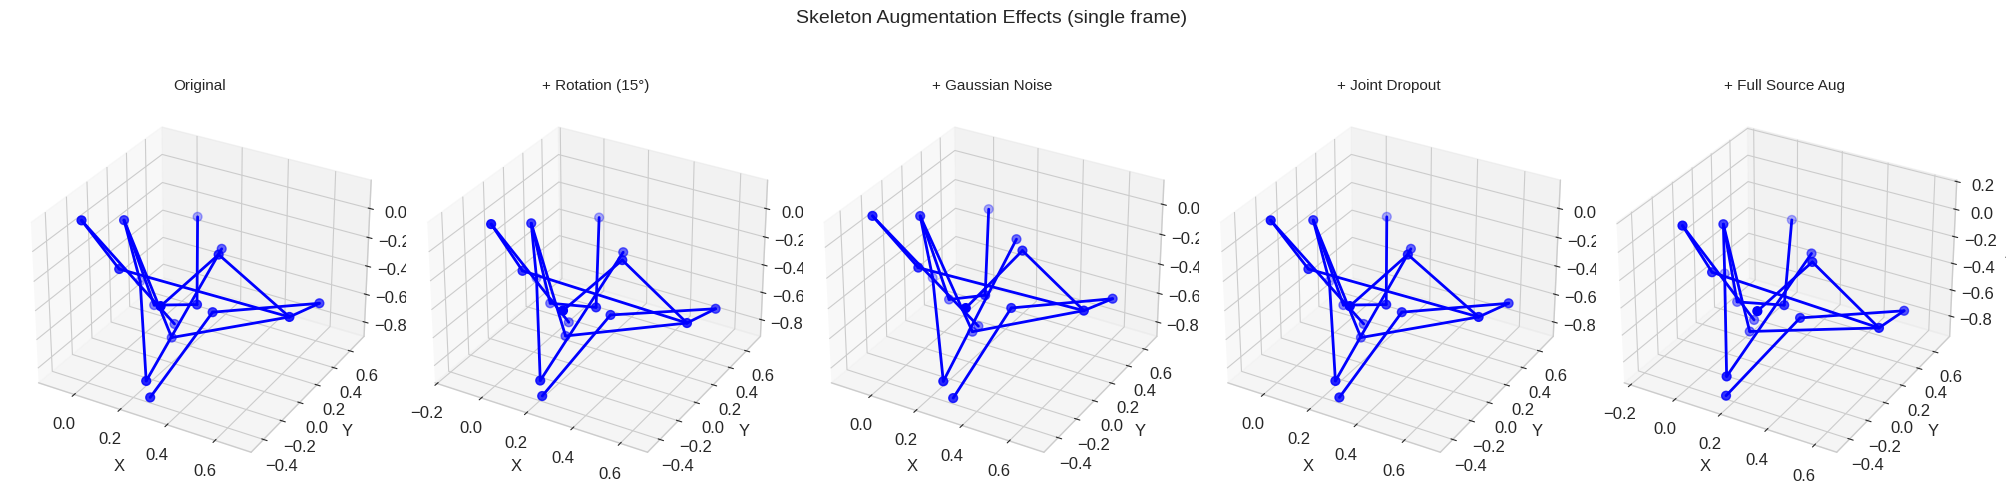

In [17]:
# ============================================================================
# Visualize augmentation effects
# ============================================================================

def visualize_skeleton_frame(ax, skeleton_frame, edges, title="", color='blue'):
    """Plot a single skeleton frame in 3D."""
    ax.scatter(skeleton_frame[:, 0], skeleton_frame[:, 1], skeleton_frame[:, 2],
              c=color, s=40, zorder=5)
    for i, j in edges:
        ax.plot([skeleton_frame[i, 0], skeleton_frame[j, 0]],
               [skeleton_frame[i, 1], skeleton_frame[j, 1]],
               [skeleton_frame[i, 2], skeleton_frame[j, 2]],
               c=color, linewidth=2)
    ax.set_title(title, fontsize=11)
    ax.set_xlabel('X'); ax.set_ylabel('Y'); ax.set_zlabel('Z')


# Demo: create a synthetic test skeleton and show augmentation effects
test_skel = np.random.randn(64, 17, 3).astype(np.float32) * 0.3
test_skel = hip_center_normalize(test_skel)

fig = plt.figure(figsize=(20, 5))
augmentors = [
    ("Original", SkeletonAugmentor()),
    ("+ Rotation (15°)", SkeletonAugmentor(rotation_range=15)),
    ("+ Gaussian Noise", SkeletonAugmentor(gaussian_noise_std=0.02)),
    ("+ Joint Dropout", SkeletonAugmentor(joint_dropout_prob=0.3)),
    ("+ Full Source Aug", SOURCE_AUGMENTOR),
]

for i, (name, aug) in enumerate(augmentors):
    ax = fig.add_subplot(1, 5, i+1, projection='3d')
    augmented = aug(test_skel)
    frame = augmented[0]  # first frame
    visualize_skeleton_frame(ax, frame, UNIFIED_EDGES, title=name)

plt.suptitle("Skeleton Augmentation Effects (single frame)", fontsize=14, y=1.02)
plt.tight_layout()
plt.savefig(str(OUTPUT_DIR / 'figures' / 'augmentation_demo.pdf'), bbox_inches='tight', dpi=150)
plt.show()

## 8. Action Precedence Automaton (APA)

In [18]:
# ============================================================================
# Action Precedence Automaton (APA)
# ============================================================================

import torch
import torch.nn.functional as F


class ActionPrecedenceAutomaton:
    """
    Encodes valid action transitions in industrial assembly workflows.
    Used as a structural prior to reject physically impossible predictions.
    """
    
    def __init__(self, num_classes=NUM_CLASSES, smoothing=1e-3, temperature=1.0):
        self.num_classes = num_classes
        self.smoothing = smoothing
        self.temperature = temperature
        self.transition_counts = np.zeros((num_classes, num_classes), dtype=np.float64)
        self.transition_probs = None
    
    def fit(self, action_sequences: List[List[int]]) -> 'ActionPrecedenceAutomaton':
        """Learn transition probabilities from labeled action sequences."""
        self.transition_counts = np.zeros((self.num_classes, self.num_classes), dtype=np.float64)
        
        for seq in action_sequences:
            for i in range(len(seq) - 1):
                if seq[i] != seq[i + 1]:  # skip self-loops
                    self.transition_counts[seq[i], seq[i + 1]] += 1
        
        smoothed = self.transition_counts + self.smoothing
        self.transition_probs = smoothed / smoothed.sum(axis=1, keepdims=True).clip(1e-10)
        return self
    
    def fit_from_prior(self) -> 'ActionPrecedenceAutomaton':
        """Build hand-designed prior from assembly domain knowledge."""
        prior = np.ones((self.num_classes, self.num_classes)) * 0.02
        
        likely = {
            0: [1, 6, 7],       1: [2, 0],           2: [3, 4],
            3: [5, 10],          4: [5, 10],          5: [0, 6, 8],
            6: [1, 2, 0],        7: [0, 9, 11],       8: [0, 11, 9],
            9: [0, 1],           10: [0, 9, 11],      11: [3, 4],
            12: list(range(13)),
        }
        for src, targets in likely.items():
            for tgt in targets:
                prior[src, tgt] = 0.8 / len(targets)
        
        self.transition_probs = prior / prior.sum(axis=1, keepdims=True).clip(1e-10)
        return self
    
    def constrain_predictions(self, logits: torch.Tensor, prev_actions: torch.Tensor) -> torch.Tensor:
        """
        Multiply softmax probs by transition priors from previous action.
        
        Args:
            logits: (B, C) raw model logits
            prev_actions: (B,) previous action indices
        Returns:
            constrained_logits: (B, C)
        """
        device = logits.device
        trans = torch.tensor(self.transition_probs, dtype=torch.float32, device=device)
        priors = trans[prev_actions]  # (B, C)
        priors = priors ** (1.0 / self.temperature)
        priors = priors / priors.sum(dim=-1, keepdim=True)
        
        probs = F.softmax(logits, dim=-1) * priors
        probs = probs / probs.sum(dim=-1, keepdim=True).clamp(min=1e-10)
        return torch.log(probs + 1e-10)


# Build APA with hand-designed prior (will be re-fitted on training data later)
apa = ActionPrecedenceAutomaton()
apa.fit_from_prior()

print("APA built with prior knowledge ✓")
print(f"Transition matrix shape: {apa.transition_probs.shape}")

APA built with prior knowledge ✓
Transition matrix shape: (13, 13)


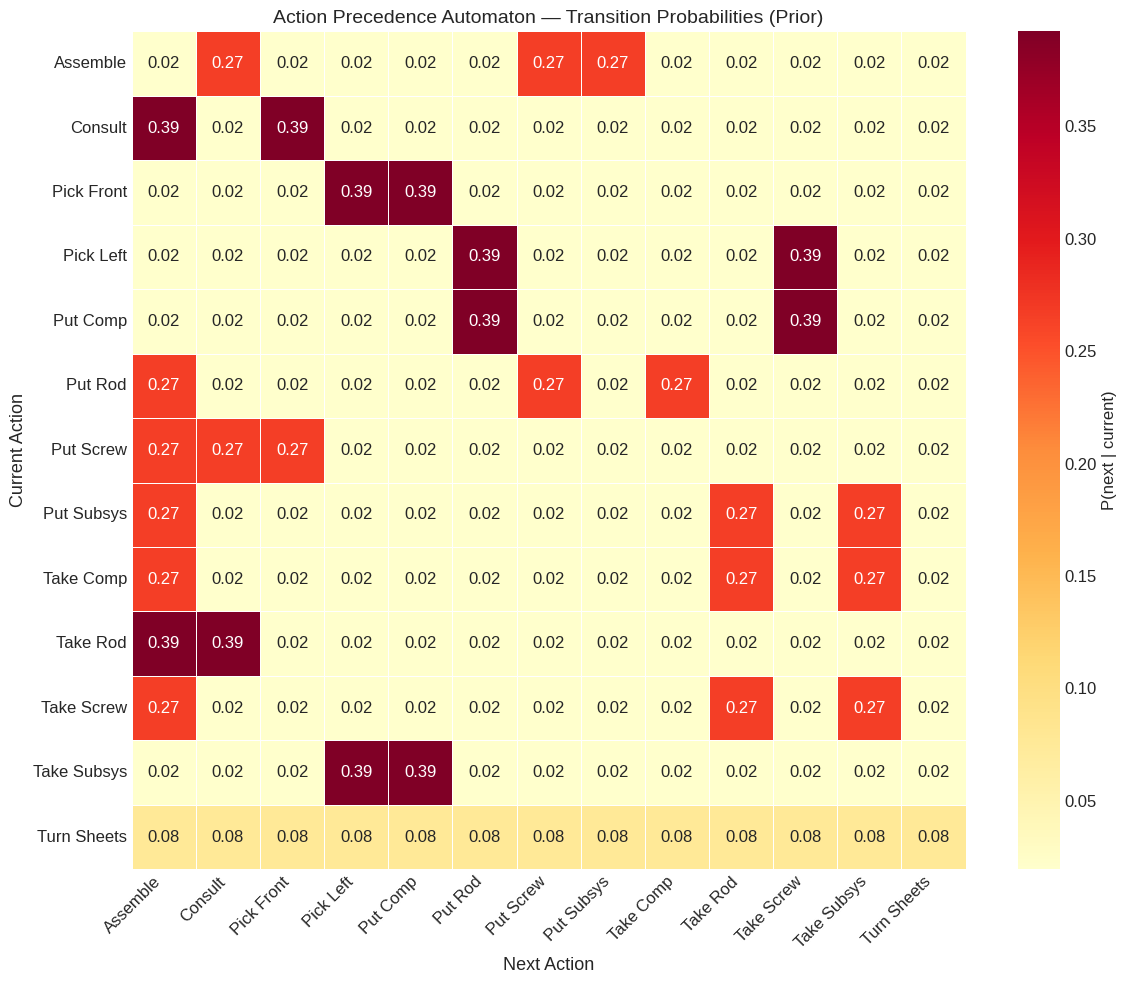

In [19]:
# ============================================================================
# Visualize APA transition matrix
# ============================================================================

fig, ax = plt.subplots(figsize=(12, 10))

short_names = [SHORT_LABELS[i] for i in range(NUM_CLASSES)]
sns.heatmap(
    apa.transition_probs, ax=ax, cmap='YlOrRd',
    xticklabels=short_names, yticklabels=short_names,
    annot=True, fmt='.2f', linewidths=0.5,
    cbar_kws={'label': 'P(next | current)'},
)
ax.set_xlabel('Next Action', fontsize=13)
ax.set_ylabel('Current Action', fontsize=13)
ax.set_title('Action Precedence Automaton — Transition Probabilities (Prior)', fontsize=14)
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)

plt.tight_layout()
plt.savefig(str(OUTPUT_DIR / 'figures' / 'apa_transition_matrix.pdf'), bbox_inches='tight', dpi=150)
plt.show()

## 9. Create LOSO Splits

In [20]:
# ============================================================================
# Leave-One-Subject-Out (LOSO) Split Generation
# ============================================================================
import re

def create_loso_splits(
    processed_dir: Path,
    output_dir: Path,
    dataset_name: str,
):
    """
    Create LOSO cross-validation splits.
    
    Expects processed_dir to contain .npz files organized by subject.
    Subject ID is extracted from directory name or filename.
    """
    output_dir.mkdir(parents=True, exist_ok=True)
    
    # Find all processed files
    files = sorted(processed_dir.rglob("*.npz"))
    if not files:
        print(f"No .npz files found in {processed_dir}")
        return {}
    
    file_subjects = {}
    for f in files:
        path_str = str(f.relative_to(processed_dir))
        
        # Match LMVR_10, Subject_01, S01, etc.
        match = re.search(r'LMVR_(\d+)', path_str) or re.search(r'[Ss](?:ubject)?[_-]?(\d+)', path_str)
        if match:
            subject_id = int(match.group(1))
        else:
            subject_id = abs(hash(f.stem)) % 100
        
        file_subjects[path_str] = subject_id
    
    subjects = sorted(set(file_subjects.values()))
    print(f"Dataset: {dataset_name}")
    print(f"  Found {len(files)} files across {len(subjects)} subjects")
    print(f"  Subject IDs: {subjects}")
    
    # Create LOSO splits
    splits = {}
    for test_subject in subjects:
        train_files = [f for f, s in file_subjects.items() if s != test_subject]
        test_files = [f for f, s in file_subjects.items() if s == test_subject]
        
        splits[f"fold_{test_subject}"] = {
            "test_subject": test_subject,
            "train_files": train_files,
            "test_files": test_files,
            "n_train": len(train_files),
            "n_test": len(test_files),
        }
    
    # Save splits
    split_file = output_dir / f"{dataset_name}_loso_splits.json"
    with open(split_file, 'w') as f:
        json.dump(splits, f, indent=2)
    
    print(f"  Saved {len(splits)} LOSO folds to {split_file}")
    for fold_name, fold in list(splits.items())[:5]:
        print(f"    {fold_name}: train={fold['n_train']}, test={fold['n_test']}")
    if len(splits) > 5:
        print(f"    ... and {len(splits) - 5} more folds.")
    
    return splits

# Create splits for both datasets
print("=" * 60)
inhard_splits = create_loso_splits(INHARD_PROCESSED, SPLITS_DIR, "inhard")
print()
inhard_dt_splits = create_loso_splits(INHARD_DT_PROCESSED, SPLITS_DIR, "inhard_dt")
print("=" * 60)


No .npz files found in /home/g0amer/Desktop/thesis/04_Cross_Modal_Digital_Twin/data/inhard/processed

Dataset: inhard_dt
  Found 4796 files across 26 subjects
  Subject IDs: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26]
  Saved 26 LOSO folds to /home/g0amer/Desktop/thesis/04_Cross_Modal_Digital_Twin/data/splits/inhard_dt_loso_splits.json
    fold_1: train=4736, test=60
    fold_2: train=4705, test=91
    fold_3: train=4468, test=328
    fold_4: train=4697, test=99
    fold_5: train=4545, test=251
    ... and 21 more folds.


## 10. EDA Summary & Dataset Statistics

In [21]:
# ============================================================================
# Compute dataset statistics
# ============================================================================

def compute_dataset_stats(processed_dir: Path, name: str):
    """Compute summary statistics for a processed dataset."""
    files = sorted(processed_dir.rglob("*.npz"))
    
    if not files:
        print(f"  No processed files found for {name}")
        return None, None, None
    
    all_pos = []
    all_vel = []
    frame_counts = []
    
    for f in tqdm(files, desc=f"Stats for {name}"):
        data = np.load(str(f))
        pos = data['positions']
        vel = data['velocities']
        
        all_pos.append(pos)
        all_vel.append(vel)
        frame_counts.append(pos.shape[0])
    
    all_pos = np.concatenate(all_pos, axis=0)
    all_vel = np.concatenate(all_vel, axis=0)
    
    stats = {
        "name": name,
        "n_files": len(files),
        "total_frames": int(all_pos.shape[0]),
        "mean_seq_len": float(np.mean(frame_counts)),
        "std_seq_len": float(np.std(frame_counts)),
        "pos_mean": all_pos.mean(axis=(0, 1)).tolist(),
        "pos_std": all_pos.std(axis=(0, 1)).tolist(),
        "vel_mean_magnitude": float(np.linalg.norm(all_vel, axis=-1).mean()),
        "vel_std_magnitude": float(np.linalg.norm(all_vel, axis=-1).std()),
    }
    
    return stats, all_pos, all_vel


print("Computing dataset statistics...")
dt_stats, dt_pos, dt_vel = compute_dataset_stats(INHARD_DT_PROCESSED, "InHARD-DT")
real_stats, real_pos, real_vel = compute_dataset_stats(INHARD_PROCESSED, "InHARD")

print("\n--- Dataset Statistics ---")
for stats in [dt_stats, real_stats]:
    if stats is not None:
        print(f"\n{stats['name']}:")
        print(f"  Files: {stats['n_files']:,}")
        print(f"  Total frames: {stats['total_frames']:,}")
        print(f"  Avg sequence length: {stats['mean_seq_len']:.0f} ± {stats['std_seq_len']:.0f} frames")
        print(f"  Position std (xyz): {[f'{v:.4f}' for v in stats['pos_std']]}")
        print(f"  Velocity magnitude: {stats['vel_mean_magnitude']:.4f} ± {stats['vel_std_magnitude']:.4f}")


Computing dataset statistics...


Stats for InHARD-DT:   0%|          | 0/4796 [00:00<?, ?it/s]

  No processed files found for InHARD

--- Dataset Statistics ---

InHARD-DT:
  Files: 4,796
  Total frames: 326,416
  Avg sequence length: 68 ± 26 frames
  Position std (xyz): ['3.8405', '4.4693', '4.1133']
  Velocity magnitude: 23.3768 ± 159.3569


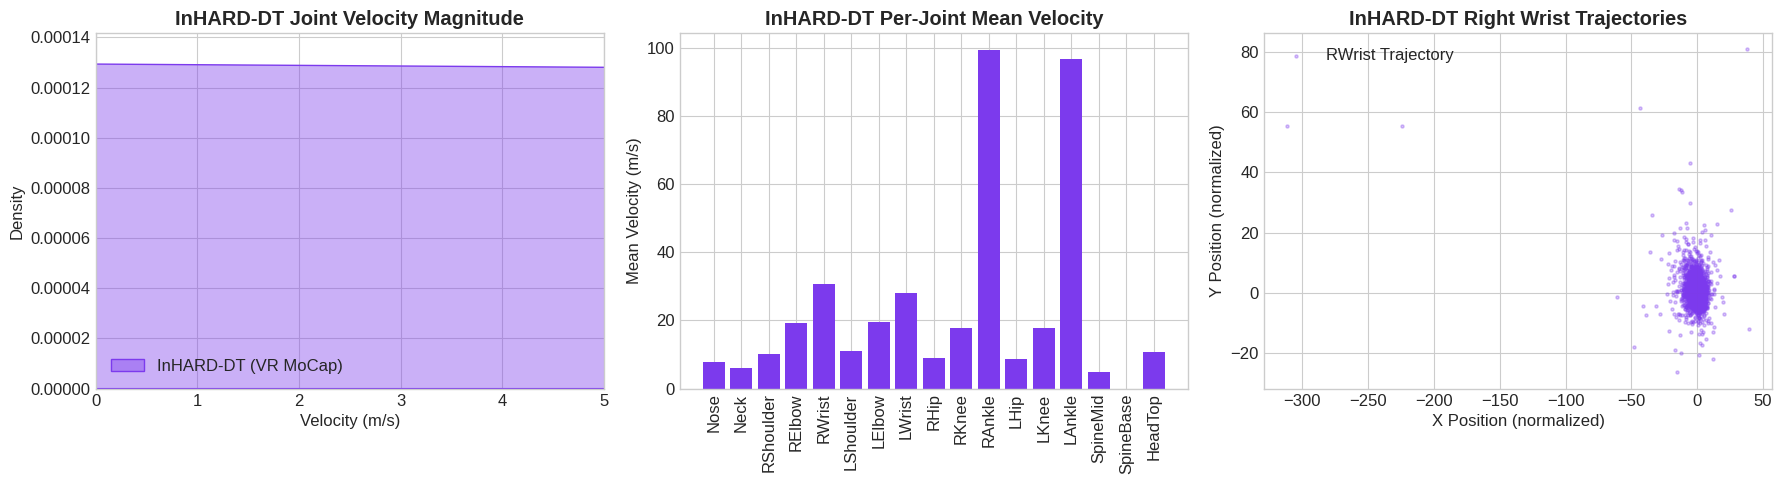

Saved EDA domain gap figure to /home/g0amer/Desktop/thesis/04_Cross_Modal_Digital_Twin/output/figures/eda_domain_gap_analysis.png ✓


In [22]:
# ============================================================================
# Visualize domain gap: velocity and motion distributions
# ============================================================================

try:
    fig, axes = plt.subplots(1, 3, figsize=(18, 5))
    
    if dt_vel is not None and real_vel is not None:
        # 1. Velocity magnitude distribution
        dt_vmag = np.linalg.norm(dt_vel, axis=-1).flatten()
        real_vmag = np.linalg.norm(real_vel, axis=-1).flatten()
        
        sns.kdeplot(dt_vmag, ax=axes[0], label='InHARD-DT (VR MoCap)', color='#7c3aed', fill=True, alpha=0.3)
        sns.kdeplot(real_vmag, ax=axes[0], label='InHARD (Real Kinect)', color='#059669', fill=True, alpha=0.3)
        axes[0].set_title("Joint Velocity Magnitude Distribution", fontweight='bold')
        axes[0].set_xlabel("Velocity (m/s)")
        axes[0].set_xlim(0, 5)
        axes[0].legend()
        
        # 2. Per-joint velocity comparison (wrist vs ankle vs head)
        dt_joint_v = np.linalg.norm(dt_vel, axis=-1).mean(axis=0) # (17,)
        real_joint_v = np.linalg.norm(real_vel, axis=-1).mean(axis=0)
        
        x = np.arange(len(UNIFIED_JOINT_NAMES))
        width = 0.35
        axes[1].bar(x - width/2, dt_joint_v, width, label='InHARD-DT', color='#7c3aed')
        axes[1].bar(x + width/2, real_joint_v, width, label='InHARD', color='#059669')
        axes[1].set_xticks(x)
        axes[1].set_xticklabels(UNIFIED_JOINT_NAMES, rotation=90)
        axes[1].set_title("Mean Per-Joint Velocity", fontweight='bold')
        axes[1].set_ylabel("Mean Velocity (m/s)")
        axes[1].legend()
        
        # 3. Position workspace coverage
        axes[2].scatter(dt_pos[::10, 4, 0], dt_pos[::10, 4, 1], alpha=0.2, s=5, label='InHARD-DT (RWrist)', color='#7c3aed')
        axes[2].scatter(real_pos[::10, 4, 0], real_pos[::10, 4, 1], alpha=0.2, s=5, label='InHARD (RWrist)', color='#059669')
        axes[2].set_title("Right Wrist Workspace Trajectories", fontweight='bold')
        axes[2].set_xlabel("X Position (normalized)")
        axes[2].set_ylabel("Y Position (normalized)")
        axes[2].legend()
        
    elif dt_vel is not None:
        dt_vmag = np.linalg.norm(dt_vel, axis=-1).flatten()
        sns.kdeplot(dt_vmag, ax=axes[0], label='InHARD-DT (VR MoCap)', color='#7c3aed', fill=True, alpha=0.4)
        axes[0].set_title("InHARD-DT Joint Velocity Magnitude", fontweight='bold')
        axes[0].set_xlabel("Velocity (m/s)")
        axes[0].set_xlim(0, 5)
        axes[0].legend()
        
        dt_joint_v = np.linalg.norm(dt_vel, axis=-1).mean(axis=0)
        axes[1].bar(range(len(UNIFIED_JOINT_NAMES)), dt_joint_v, color='#7c3aed')
        axes[1].set_xticks(range(len(UNIFIED_JOINT_NAMES)))
        axes[1].set_xticklabels(UNIFIED_JOINT_NAMES, rotation=90)
        axes[1].set_title("InHARD-DT Per-Joint Mean Velocity", fontweight='bold')
        axes[1].set_ylabel("Mean Velocity (m/s)")
        
        axes[2].scatter(dt_pos[::10, 4, 0], dt_pos[::10, 4, 1], alpha=0.3, s=5, label='RWrist Trajectory', color='#7c3aed')
        axes[2].set_title("InHARD-DT Right Wrist Trajectories", fontweight='bold')
        axes[2].set_xlabel("X Position (normalized)")
        axes[2].set_ylabel("Y Position (normalized)")
        axes[2].legend()
    else:
        print("No processed datasets available for visualization.")
        
    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / "figures" / "eda_domain_gap_analysis.png", dpi=300)
    plt.show()
    print(f"Saved EDA domain gap figure to {OUTPUT_DIR / 'figures' / 'eda_domain_gap_analysis.png'} ✓")
except Exception as e:
    print(f"Visualization error: {e}")


## 11. Save Processed Metadata & Summary

---

### ✅ Notebook 01 Complete

**Outputs saved:**
- `data/inhard/processed/*.npz` — Unified 17-joint skeletons (positions, velocities, accelerations, bone angles)
- `data/inhard_dt/processed/*.npz` — Same format from Digital Twin
- `data/splits/inhard_loso_splits.json` — LOSO fold definitions
- `data/splits/inhard_dt_loso_splits.json`
- `output/figures/adjacency_matrix.pdf`
- `output/figures/augmentation_demo.pdf`
- `output/figures/apa_transition_matrix.pdf`
- `output/figures/domain_gap_analysis.pdf`

**Next notebook:** `02_Models_and_Losses.ipynb` — CTR-GCN backbone, CSTA loss, anticipation decoder

In [23]:
print("=" * 60)
print("Notebook 01 — EDA & Data Preparation — COMPLETE")
print("=" * 60)

Notebook 01 — EDA & Data Preparation — COMPLETE
